# 03 · Looking inside: where does the CNN look? (Grad-CAM)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/FashionNet/blob/main/notebooks/03_grad_cam_looking_inside.ipynb)

**After this notebook you will be able to** compute a Grad-CAM heat map from scratch, read it, and, just as important,
explain what it does *not* tell you.

*Time: about 30 minutes (training takes about one minute). Prerequisites: notebooks 01 and 02.*

## 1 · The big question

Our CNN says "coat" with 81% confidence. **Why?** A doctor who reads an X-ray with a computer's help,
or a shop owner who wants to trust the sorting machine, will ask exactly this. A single probability is not an explanation.

A popular first answer is a **heat map**: a coloured picture that marks the parts of the input that
mattered for the decision. We build one of the best-known versions, **Grad-CAM** (Selvaraju et al., 2017), and then test how
far it can be trusted.

## 2 · Intuition first: asking the last convolution layer

Remember from notebook 01: the last convolution layer produces 32 *feature maps*, small pictures that each light up where one learned pattern
is present (a collar, a strap, a heel). After that layer the network only mixes these maps into ten class scores.

**Idea:** for the class we want to explain, ask *"if this feature map became a little stronger, how much would the class score rise?"*
Maps that raise the score get a big positive weight, maps that lower it get a negative weight. Then add the maps up using those weights.
The result lights up the places where the "helpful" patterns were found.

Analogy: ten people shout votes; you listen to the 32 microphones at the end of the hall (the feature maps) and
ask, for each microphone, "does turning you up make the vote for *coat* louder?"

**Math (light).** Let $A^k$ be the $k$-th feature map (an 11 × 11 grid for our network) and $y^c$ the score of class $c$ *before* the softmax.

$$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}} \qquad\qquad L^c = \mathrm{ReLU}\Big(\sum_k \alpha_k^c A^k\Big)$$

- $A^k_{ij}$: value of feature map $k$ at row $i$, column $j$;
- $\partial y^c / \partial A^k_{ij}$: how much the score would change if that value changed a little (the gradient, computed by the same machinery that trains the network);
- $Z$ = 11 × 11, the number of positions, so $\alpha^c_k$ is the *average* gradient: one weight per map;
- $\mathrm{ReLU}(v)=\max(0,v)$ keeps only evidence *for* the class;
- $L^c$ is the final 11 × 11 map; we stretch it to 28 × 28 so it can be laid over the picture.

> **Predict:** will the heat map cover the whole garment, or only parts of it?

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/FashionNet.git"], check=True)
    os.chdir("FashionNet/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import numpy as np
import matplotlib.pyplot as plt

from src import fashion
import keras, tensorflow as tf
from src.fashion import CLASS_NAMES, save_figure

fashion.set_seed()                 # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

First we need a trained network. This is exactly the CNN of notebook 01 (20,000 training pictures, 10 epochs, seed 42),
so we expect the same test accuracy, 0.8670.

In [2]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = fashion.load_fashion(n_train=20000, n_val=5000)

fashion.set_seed()
model = fashion.compile_model(fashion.build_cnn())
model.fit(x_train, y_train, epochs=10, batch_size=64, validation_data=(x_val, y_val), verbose=0)
print("test accuracy:", round(model.evaluate(x_test, y_test, verbose=0)[1], 4))

test accuracy: 0.867


## 3 · The recipe, step by step on one picture

We pick the first test picture that the CNN classifies correctly as a *pullover* and follow the recipe from the formulas.

In [3]:
predicted = model.predict(x_test, verbose=0).argmax(axis=1)
i = int(np.flatnonzero((y_test == 2) & (predicted == 2))[0])     # first correctly recognised pullover
image = x_test[i]

conv_layer = [layer for layer in model.layers if isinstance(layer, keras.layers.Conv2D)][-1]

with tf.GradientTape() as tape:
    h = tf.convert_to_tensor(image[None])
    for layer in model.layers[:-1]:              # everything except the last (softmax) layer
        h = layer(h)
        if layer is conv_layer:
            A = h                                # the feature maps, shape (1, 11, 11, 32)
    head = model.layers[-1]
    logits = tf.matmul(h, head.kernel) + head.bias      # class scores BEFORE the softmax
    score = logits[0, 2]                                 # class 2 = pullover

gradients = tape.gradient(score, A)              # d score / d A, same shape as A
alpha = tf.reduce_mean(gradients, axis=(1, 2))   # average over the 11 x 11 positions: one weight per map
raw_map = tf.reduce_sum(A * alpha[:, None, None, :], axis=-1)[0]   # weighted sum of the 32 maps
cam = fashion.grad_cam(model, image, class_index=2)[0]             # our helper does the same, plus ReLU and stretching

print("feature maps A:", tuple(A.shape), "  weights alpha:", tuple(alpha.shape))
print("weights range : %.4f to %.4f" % (alpha.numpy().min(), alpha.numpy().max()))
print("share of the 11 x 11 weighted sum that is positive: %.0f%%" % (100 * (raw_map.numpy() > 0).mean()))

feature maps A: (1, 11, 11, 32)   weights alpha: (1, 32)
weights range : -0.0098 to 0.0047
share of the 11 x 11 weighted sum that is positive: 12%


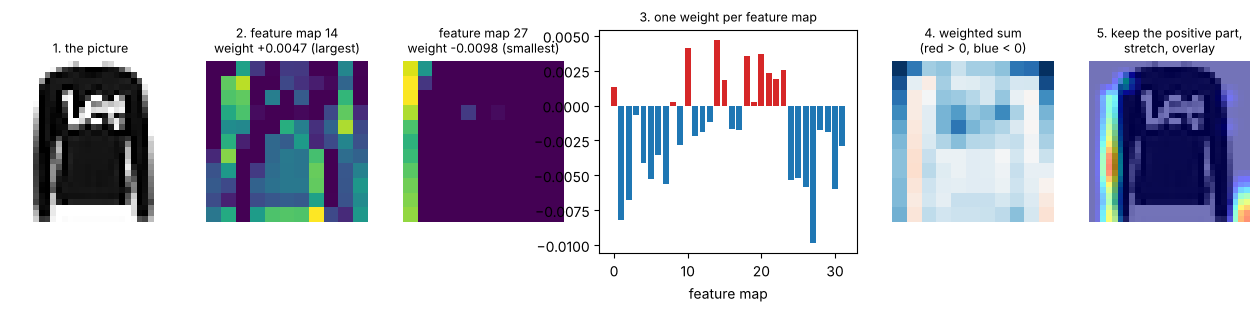

In [4]:
fig = fashion.plot_gradcam_steps(image[:, :, :], A.numpy()[0], alpha.numpy()[0], raw_map.numpy(), cam)
save_figure(fig, "03_gradcam_steps.png")
plt.show()

**What to notice.** Panel 2 and 3 are two of the 32 feature maps (11 x 11, bright = strong response). Panel 3 shows the 32 weights $\alpha_k$:
red bars are maps that raise the "pullover" score, blue bars maps that lower it. The weights are tiny numbers (see the printed range above) because the gradient of the score is spread over 32 x 121 values;
only the *relative* size matters. The weighted sum (panel 4) is negative almost everywhere (the printed share of positive cells is small), so the ReLU removes most of it.
What survives (panel 5) is a narrow strip along the left edge of the left sleeve and a spot in the lower right corner: not the print on the chest and not the body of the pullover, which was not what I would have guessed.
This is already a first lesson: **the network's evidence is not where a human would look.**

*Figure: the Grad-CAM recipe for one test picture of a pullover, in five steps.*

### Check yourself

1. Why do we apply ReLU to the weighted sum?
2. Why 11 × 11 and not 28 × 28? What does that mean for the sharpness of the heat map?

<details>
<summary>Answers</summary>


1. Negative values mean "this place speaks *against* the class". Grad-CAM is meant to show evidence *for* the class, so negative parts are set to zero.
2. The heat map is built from the last convolution layer, where a position summarises a 3 × 3 neighbourhood of the previous, already pooled map.
   An 11 × 11 map stretched to 28 × 28 is blurry by construction: Grad-CAM shows *regions*, not exact pixels.

</details>

## 4 · One example per class

Now the helper `fashion.grad_cam` for ten test pictures, one correctly recognised example of every class.

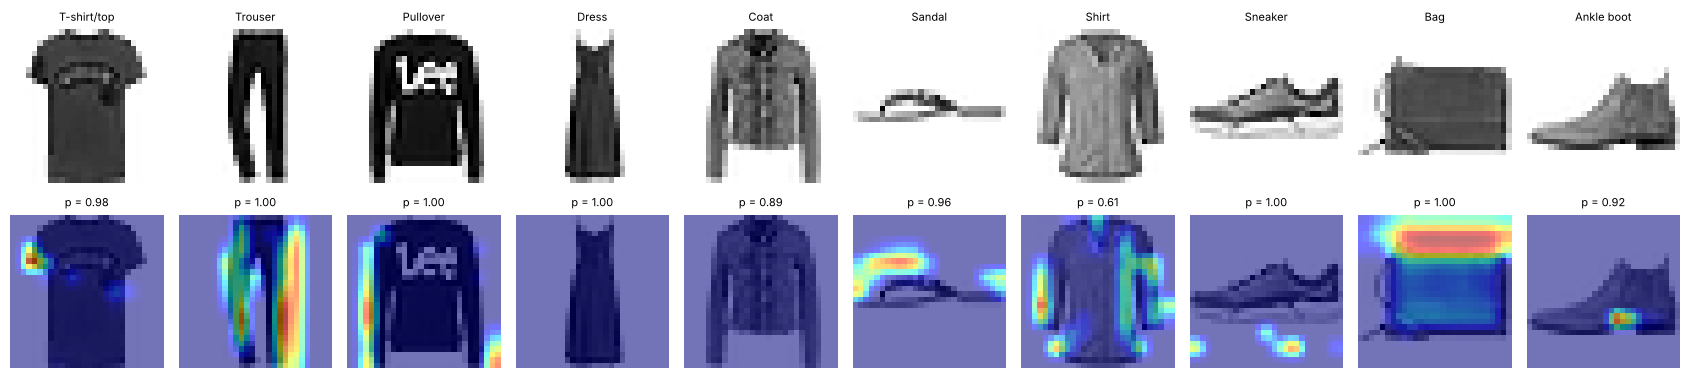

In [5]:
fig, axes = plt.subplots(2, 10, figsize=(17, 4))
for k in range(10):
    j = int(np.flatnonzero((y_test == k) & (predicted == k))[0])
    heat, _, probability = fashion.grad_cam(model, x_test[j])
    axes[0, k].imshow(x_test[j, :, :, 0], cmap="gray_r"); axes[0, k].axis("off")
    axes[0, k].set_title(CLASS_NAMES[k], fontsize=8)
    fashion.overlay(axes[1, k], x_test[j], heat)
    axes[1, k].set_title(f"p = {probability:.2f}", fontsize=8)
fig.tight_layout()
save_figure(fig, "03_gradcam_per_class.png")
plt.show()

**What to notice.** The heat maps are different for each class, and several look sensible: for the **trouser** both legs light up, for the **sandal** the strap area, for the **bag** the top edge, for the **ankle boot** the ankle region.
For the **T-shirt** only the edge of the left sleeve is marked, for the **sneaker** the marks are mostly small spots *below* and beside the shoe, and for the **dress** and the **coat** the heat map is **completely empty** (no positive evidence found by this method) even though both are recognised with high confidence.
So the same method gives convincing pictures for some classes and nothing useful for others.

*Figure: one correctly recognised test picture per class (top) with its Grad-CAM overlay (bottom, red = strong evidence for the predicted class) and the predicted probability p.*

## 5 · Why was it wrong? Explain a mistake

A good use of a heat map is to look at *errors*. For a wrong prediction we can ask for the map of the predicted class
and the map of the true class.

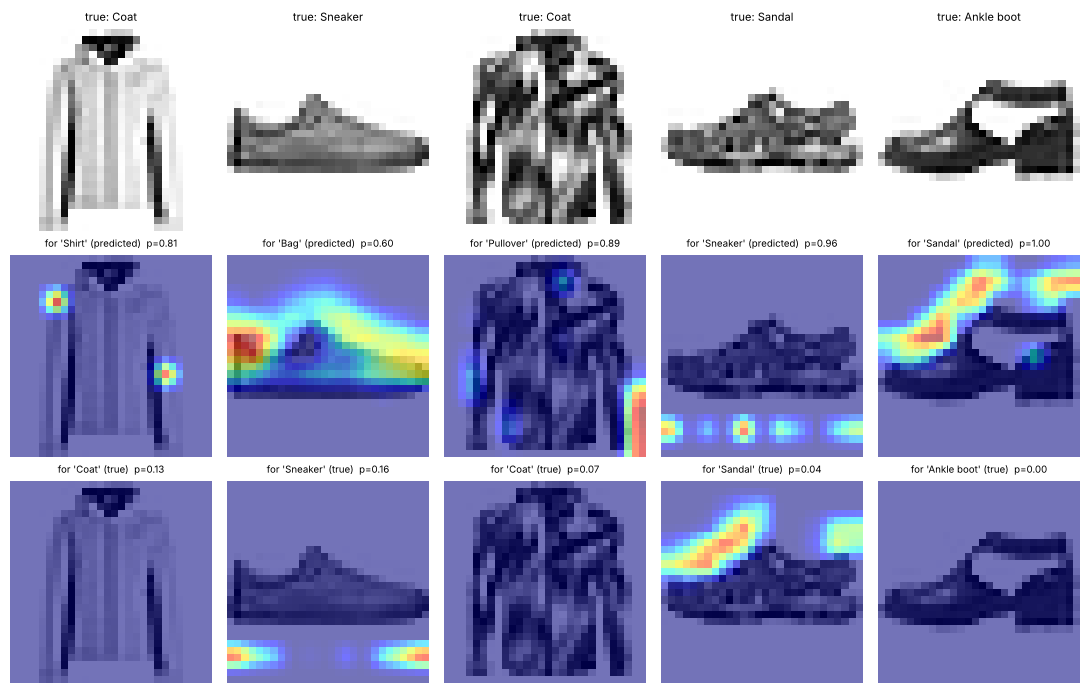

In [6]:
wrong = np.flatnonzero(predicted != y_test)[:5]
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for col, j in enumerate(wrong):
    wrong_class, true_class = predicted[j], y_test[j]
    axes[0, col].imshow(x_test[j, :, :, 0], cmap="gray_r"); axes[0, col].axis("off")
    axes[0, col].set_title(f"true: {CLASS_NAMES[true_class]}", fontsize=8)
    heat, _, p = fashion.grad_cam(model, x_test[j], class_index=wrong_class)
    fashion.overlay(axes[1, col], x_test[j], heat); axes[1, col].set_title(f"for '{CLASS_NAMES[wrong_class]}' (predicted)  p={p:.2f}", fontsize=7)
    heat, _, p = fashion.grad_cam(model, x_test[j], class_index=true_class)
    fashion.overlay(axes[2, col], x_test[j], heat); axes[2, col].set_title(f"for '{CLASS_NAMES[true_class]}' (true)  p={p:.2f}", fontsize=7)
fig.tight_layout()
save_figure(fig, "03_gradcam_mistakes.png")
plt.show()

**What to notice.** For the five first mistakes, the map for the **predicted** class (middle row) is not empty: for example the "bag" map of the sneaker covers its two ends, and the "sandal" map of the ankle boot covers the strap region, which is plausible, since that boot does have straps.
The map for the **true** class (bottom row) is empty in three of the five pictures (both coats and the ankle boot), which means the method finds no positive evidence for the true class there. In the sandal picture, where the true class gets a map, the network still prefers "sneaker" with 96%.
This is how a heat map helps debugging: it points at the region that pulled the network towards the wrong class. It does not tell us *why* those pixels were misleading.

*Figure: five mistakes. Top: the picture with its true class. Middle: Grad-CAM for the wrongly predicted class. Bottom: Grad-CAM for the true class. p is the probability the network gives to that class.*

## 6 · How far can we trust the heat map? A test

A heat map *looks* convincing, which is exactly why it needs a test. Here is a simple one, an **occlusion test**.
If the highlighted place really mattered, then covering it should hurt the prediction more than covering some other place.
For 1,000 test pictures we cover a 7 × 7 square (set to background) at three different places and measure how much the probability
of the originally predicted class drops:

- at the **peak of the Grad-CAM map**,
- at a **random pixel of the garment** (a pixel that is not background),
- at a **random pixel anywhere** in the picture.

Some heat maps are completely empty (all values zero after the ReLU); we count them and leave them out of the comparison.

> **Predict:** which of the three will hurt the prediction most?

In [7]:
N = 1000
images = x_test[:N]
cams = np.array([fashion.grad_cam(model, im)[0] for im in images])
empty = cams.max(axis=(1, 2)) == 0
print(f"pictures with a completely empty heat map: {empty.sum()} of {N}")

keep = np.flatnonzero(~empty)
rng = np.random.default_rng(0)
peak = [np.unravel_index(cams[k].argmax(), (28, 28)) for k in keep]
garment = []
for k in keep:
    rows, cols = np.nonzero(images[k, :, :, 0] > 0.1)
    pick = rng.integers(len(rows))
    garment.append((rows[pick], cols[pick]))
anywhere = [(int(rng.integers(28)), int(rng.integers(28))) for _ in keep]

print(f"{'where the 7x7 square is placed':32s} mean drop of the predicted-class probability")
for name, centres in [("peak of the Grad-CAM map", peak), ("random garment pixel", garment), ("random pixel anywhere", anywhere)]:
    drop = fashion.occlusion_probability_drop(model, images[keep], centres, size=7)
    print(f"{name:32s} {drop.mean():.3f}")

pictures with a completely empty heat map: 263 of 1000
where the 7x7 square is placed   mean drop of the predicted-class probability


peak of the Grad-CAM map         0.080


random garment pixel             0.116


random pixel anywhere            0.059


**What to notice.**

- In 263 of the 1,000 pictures the heat map is completely empty, so for about a quarter of the pictures this method gives no answer at all.
- Covering the **peak of the heat map** lowers the probability by 0.080 on average, only a little more than covering a **random place anywhere** in the picture (0.059; many of those squares fall on the empty background where nothing can be lost), and **less** than covering a **random pixel of the garment** (0.116).
- So this test does **not** support the claim that the Grad-CAM peak marks the most important place for this network. It is a crude test (one model, one seed, one square size) and it is not a proof that Grad-CAM is wrong, but it is a good reason not to over-read the pictures.

Possible reasons, which we have *not* tested: the heat map is coarse (11 x 11); the evidence for a class is spread over several places; the max-pooling layer after the last convolution passes gradient only through the largest value of each 2 x 2 block and drops the last row and column of the 11 x 11 maps; and the 7 x 7 occlusion itself changes the picture in other ways.

A heat map is a **hypothesis** about the network. A test like this one is how a hypothesis becomes (or fails to become) evidence.

### Check yourself

1. In this test, which result would have supported the claim "Grad-CAM marks the most important place"?
2. Name one reason why covering a 7 × 7 square can be a poor test of importance.

<details>
<summary>Answers</summary>


1. A clearly larger probability drop when covering the Grad-CAM peak than when covering random garment pixels.
2. The evidence for a class is often spread over several places (two sleeves, two legs). Covering one place leaves the others, so the prediction hardly changes even if that place mattered.
   Also, a square of background is itself an unusual picture, which can change the prediction for reasons unrelated to the covered content.

</details>

## 7 · Common mistakes

- **Treating the heat map as the explanation.** It shows *where* the gradient evidence is, not *what* the network concluded from it or *why*.
- **Over-reading a single picture.** Look at many pictures, at mistakes, and test the heat map (as in section 6) before trusting it.
- **Forgetting the resolution.** 11 × 11 stretched to 28 × 28 is blurry; do not interpret single pixels.
- **Explaining the softmax output.** Use the score before the softmax; the softmax gradient can vanish for very confident predictions and hide the evidence.
- **Using the heat map for decisions with consequences** (for instance in medicine) without independent validation.

## 8 · Recap

- Grad-CAM weights the last convolution layer's feature maps by how much they raise the class score, adds them up and keeps the positive part.
- The map is a coarse, class-specific hint. It is useful for spotting where the network looks and for debugging mistakes.
- A heat map is a claim, not a proof: our occlusion test shows why it must be tested before it is trusted.

**Next:** the README of this repository puts the whole path side by side: what the first version of the project did in 2023, and what we built now.